#Project 10: Overfitting and Underfitting Analysis

Description:

Students will build neural network models with different levels of complexity using the same classification dataset and analyze their performance. The project demonstrates how a model can perform poorly when it is either too simple or too complex.

Task 1: Build simple neural network models with different architectures or numbers of neurons using the Iris dataset.

Task 2: Train and evaluate the models using the same training and testing data.

Task 3: Identify overfitting or underfitting and suggest methods to improve the model.

Expected Output/Result:

Students will identify examples of underfitting, appropriate fitting, and overfitting by comparing training and testing performance.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

torch.manual_seed(42)
np.random.seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cu130


## 2. Load and prepare the Iris dataset

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train_np)
X_test_np = scaler.transform(X_test_np)

X_train = torch.tensor(X_train_np, dtype=torch.float32)
X_test = torch.tensor(X_test_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
y_test = torch.tensor(y_test_np, dtype=torch.long)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])
print("Classes:", list(iris.target_names))

Training samples: 120
Testing samples: 30
Input features: 4
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## 3. Define neural networks with different complexity

In [3]:
class IrisNN(nn.Module):
    def __init__(self, architecture):
        super().__init__()
        layers = []
        input_size = 4
        for neurons in architecture:
            layers.append(nn.Linear(input_size, neurons))
            layers.append(nn.ReLU())
            input_size = neurons
        layers.append(nn.Linear(input_size, 3))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

architectures = {
    "Simple": [2],
    "Medium": [16],
    "Complex": [128, 128]
}
print("Architectures:", architectures)

Architectures: {'Simple': [2], 'Medium': [16], 'Complex': [128, 128]}


## 4. Training function

In [4]:
def train_model(architecture, epochs=300):
    torch.manual_seed(42)
    model = IrisNN(architecture)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)

    train_losses = []
    train_accuracies = []
    test_accuracies = []

    for epoch in range(epochs):
        model.train()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            train_predictions = model(X_train).argmax(dim=1)
            test_predictions = model(X_test).argmax(dim=1)
            train_accuracy = (train_predictions == y_train).float().mean().item()
            test_accuracy = (test_predictions == y_test).float().mean().item()

        train_accuracies.append(train_accuracy)
        test_accuracies.append(test_accuracy)

    return model, train_losses, train_accuracies, test_accuracies

## 5. Train all models

In [5]:
models = {}
histories = {}
results = {}

for name, architecture in architectures.items():
    print("Training", name, "model...")
    model, losses, train_acc, test_acc = train_model(architecture)
    models[name] = model
    histories[name] = {
        "loss": losses,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    }
    results[name] = {
        "Architecture": str(architecture),
        "Training Accuracy": train_acc[-1],
        "Testing Accuracy": test_acc[-1],
        "Accuracy Gap": train_acc[-1] - test_acc[-1]
    }

print("\nTraining completed.")

Training Simple model...
Training Medium model...
Training Complex model...

Training completed.


## 6. Compare performance

In [6]:
results_df = pd.DataFrame.from_dict(results, orient="index")
print(results_df.round(4).to_string())

        Architecture  Training Accuracy  Testing Accuracy  Accuracy Gap
Simple           [2]             0.9667            0.9667        0.0000
Medium          [16]             0.9833            1.0000       -0.0167
Complex   [128, 128]             1.0000            0.9667        0.0333


## 7. Plot training loss

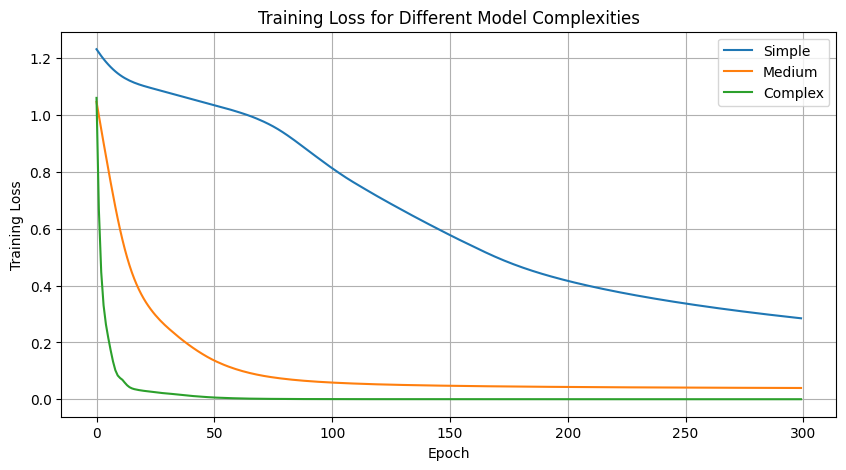

In [7]:
plt.figure(figsize=(10, 5))
for name in architectures:
    plt.plot(histories[name]["loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss for Different Model Complexities")
plt.legend()
plt.grid(True)
plt.show()

## 8. Plot training versus testing accuracy

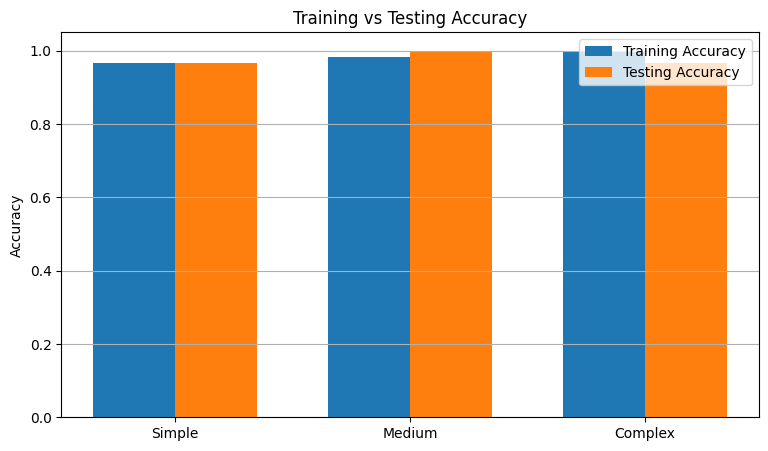

In [8]:
model_names = list(architectures.keys())
train_scores = [results[name]["Training Accuracy"] for name in model_names]
test_scores = [results[name]["Testing Accuracy"] for name in model_names]
x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, train_scores, width, label="Training Accuracy")
plt.bar(x + width / 2, test_scores, width, label="Testing Accuracy")
plt.xticks(x, model_names)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Training vs Testing Accuracy")
plt.legend()
plt.grid(axis="y")
plt.show()

## 9. Classification reports

In [9]:
for name, model in models.items():
    model.eval()
    with torch.no_grad():
        predictions = model(X_test).argmax(dim=1).cpu().numpy()
    print("\n" + name + " Model")
    print(classification_report(
        y_test.numpy(),
        predictions,
        target_names=iris.target_names,
        zero_division=0
    ))


Simple Model
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Medium Model
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Complex Model
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.0

## 10. Identify possible underfitting or overfitting

In [10]:
print("Model Fitting Analysis:\n")
for name, result in results.items():
    train_acc = result["Training Accuracy"]
    test_acc = result["Testing Accuracy"]
    gap = train_acc - test_acc

    print(name, "Model:")
    if train_acc < 0.85 and test_acc < 0.85:
        print("Possible underfitting: performance is low on both datasets.")
    elif gap > 0.10 and train_acc > test_acc:
        print("Possible overfitting: training accuracy is notably higher than testing accuracy.")
    else:
        print("No strong evidence of underfitting or overfitting from final accuracy alone.")
    print()

Model Fitting Analysis:

Simple Model:
No strong evidence of underfitting or overfitting from final accuracy alone.

Medium Model:
No strong evidence of underfitting or overfitting from final accuracy alone.

Complex Model:
No strong evidence of underfitting or overfitting from final accuracy alone.



## 11. Conclusion

This project investigated underfitting and overfitting by training neural networks of different complexities on the Iris dataset. The models were evaluated using the same training and testing data. Training and testing accuracy were compared to understand how model complexity affects generalization. Low performance on both datasets may indicate underfitting, while high training accuracy with noticeably lower testing accuracy may indicate overfitting. Possible improvements include choosing suitable model complexity, regularization, dropout, early stopping, or additional training data. The final conclusion should be based on the actual results.

